Latihan: Data Loading

In [62]:
import pandas as pd

# Memuat dataset train dan test
train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")

# Menampilkan 5 baris pertama dari data train untuk memastikan data berhasil dimuat
train.head()

,PassengerId,Pclass,Age,SibSp,Parch,Fare,Name,Sex,Ticket,Cabin,Embarked,Target
0,-0.511257,-0.68542,2.890448,-0.448235,0.0,-0.073546,359,1,166,19,2,-0.654384
1,1.181480,0.67833,-0.152535,-0.448235,0.0,-0.566115,82,1,316,19,2,-0.654384
2,1.223895,0.67833,0.140060,-0.448235,0.0,-0.569751,322,0,341,19,1,-0.654384
3,-0.592230,0.67833,-0.679205,-0.448235,0.0,-0.611099,198,1,149,19,0,-0.654384
4,0.757332,0.67833,-1.205875,-0.448235,0.0,-0.558176,110,1,287,19,2,-0.654384


In [63]:
import pandas as pd

# Memuat dataset train dan test
train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")

# Menampilkan 5 baris pertama dari data train untuk memastikan data berhasil dimuat
test.head()

,PassengerId,Pclass,Age,SibSp,Parch,Fare,Name,Sex,Ticket,Cabin,Embarked,Target
0,-0.148803,0.67833,-0.152535,-0.448235,0.0,-0.640546,208,1,382,19,1,-0.654384
1,1.524655,0.67833,1.485994,-0.448235,0.0,-0.585630,0,1,444,19,2,-0.654384
2,-0.110244,0.67833,-0.971799,-0.448235,0.0,-0.571077,94,1,424,19,1,-0.654384
3,0.514411,-2.04917,0.783768,-0.448235,0.0,2.000592,455,1,43,0,0,-0.654384
4,0.784323,0.67833,-0.152535,-0.448235,0.0,-0.563463,395,0,202,19,1,1.528156


Latihan: Data Cleaning dan Transformation

In [64]:
import pandas as pd
train = pd.read_csv('train.csv')

Mengidentifikasi Informasi Dataset

In [65]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 461 entries, 0 to 460
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  461 non-null    float64
 1   Pclass       461 non-null    float64
 2   Age          461 non-null    float64
 3   SibSp        461 non-null    float64
 4   Parch        461 non-null    float64
 5   Fare         461 non-null    float64
 6   Name         461 non-null    int64  
 7   Sex          461 non-null    int64  
 8   Ticket       461 non-null    int64  
 9   Cabin        461 non-null    int64  
 10  Embarked     461 non-null    int64  
 11  Target       461 non-null    float64
dtypes: float64(7), int64(5)
memory usage: 43.3 KB


In [66]:
train.describe(include="all")

,PassengerId,Pclass,Age,SibSp,Parch,Fare,Name,Sex,Ticket,Cabin,Embarked,Target
count,461.000000,461.000000,461.000000,461.000000,461.0,461.000000,461.000000,461.000000,461.000000,461.000000,461.000000,461.000000
mean,-0.014206,-0.002066,-0.001731,-0.004295,0.0,-0.016415,289.258134,0.744035,259.754881,20.934924,1.616052,-0.010511
std,0.996558,0.995772,1.016022,0.978265,0.0,0.973621,164.942535,0.436877,153.854104,7.817768,0.711766,0.996423
min,-1.725863,-2.049170,-2.844403,-0.448235,0.0,-1.185046,1.000000,0.000000,0.000000,2.000000,0.000000,-0.654384
25%,-0.885278,-0.685420,-0.620686,-0.448235,0.0,-0.567767,145.000000,0.000000,122.000000,19.000000,2.000000,-0.654384
50%,-0.009991,0.678330,-0.152535,-0.448235,0.0,-0.497305,291.000000,1.000000,258.000000,19.000000,2.000000,-0.654384
75%,0.838306,0.678330,0.315617,-0.448235,0.0,0.073331,423.000000,1.000000,393.000000,19.000000,2.000000,1.528156
max,1.698170,0.678330,2.890448,4.049705,0.0,3.671812,576.000000,1.000000,526.000000,61.000000,2.000000,1.528156


In [67]:
missing_values = train.isnull().sum()
missing_values[missing_values > 0]

Series([], dtype: int64)

Mengatasi Missing Value

In [68]:
less = missing_values[missing_values < 1000].index
over = missing_values[missing_values >= 1000].index

In [69]:
numeric_features = train[less].select_dtypes(include=['number']).columns
train[numeric_features] = train[numeric_features].fillna(train[numeric_features].median())

In [70]:
katagorical_features = train[less].select_dtypes(include=['object']).columns
for col in katagorical_features:
    train[col] = train[col].fillna(train[col].mode()[0])

In [71]:
df = train.drop(columns=over)

In [72]:
missing_values = df.isnull().sum()
missing_values[missing_values > 0]

Series([], dtype: int64)

Mengatasi Outliers

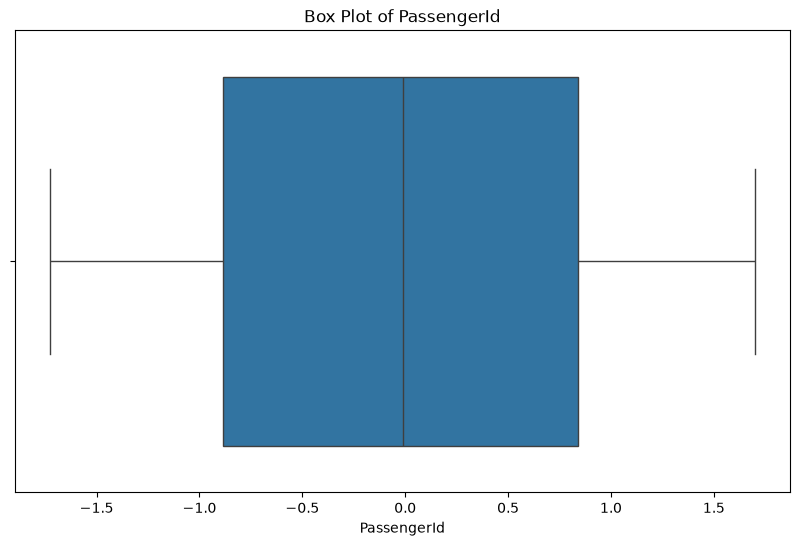

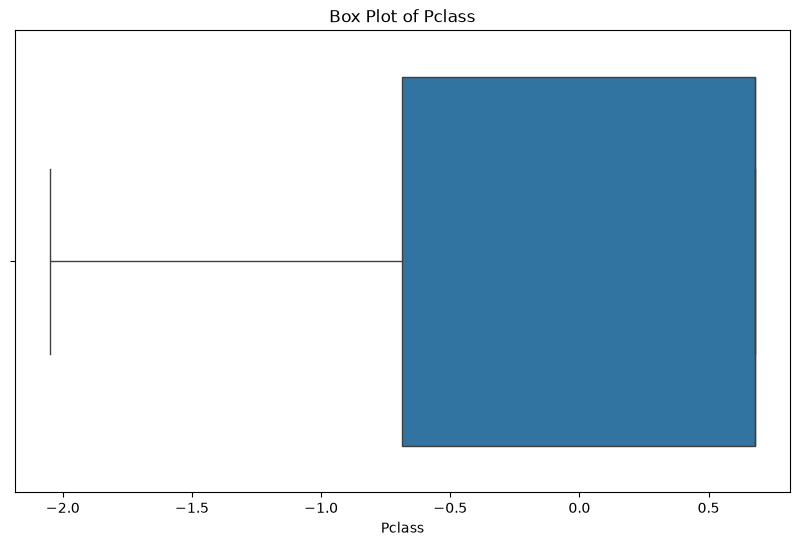

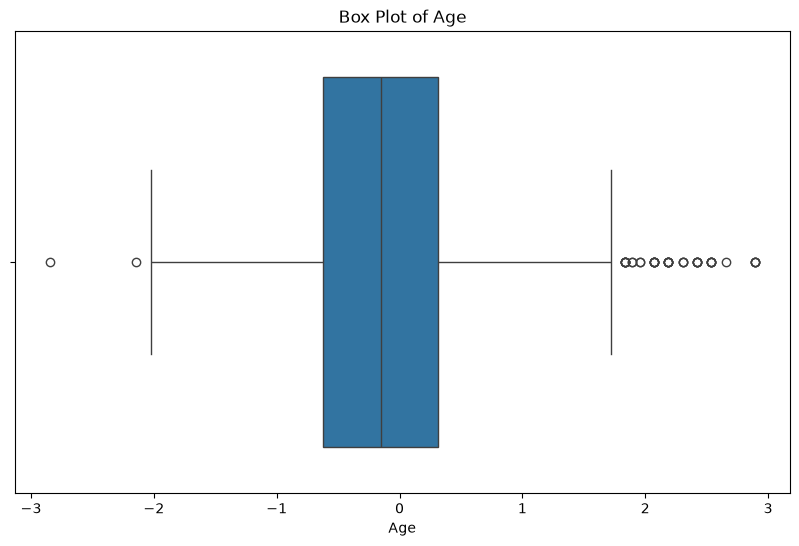

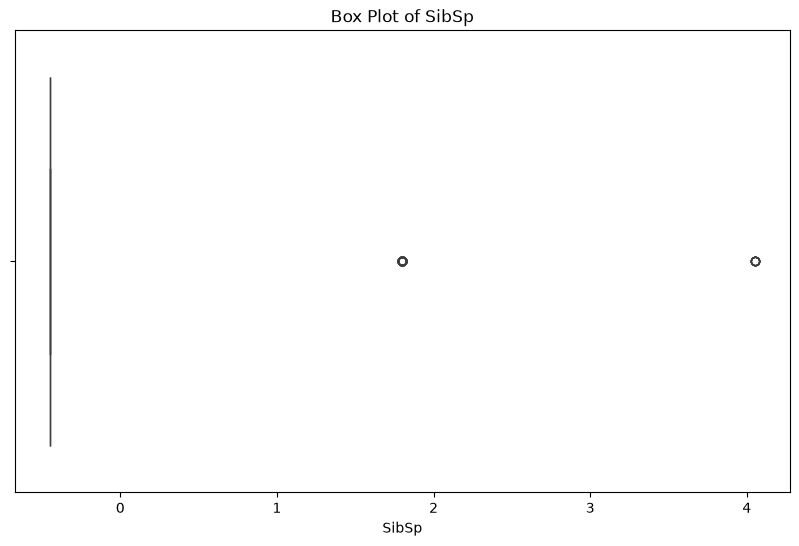

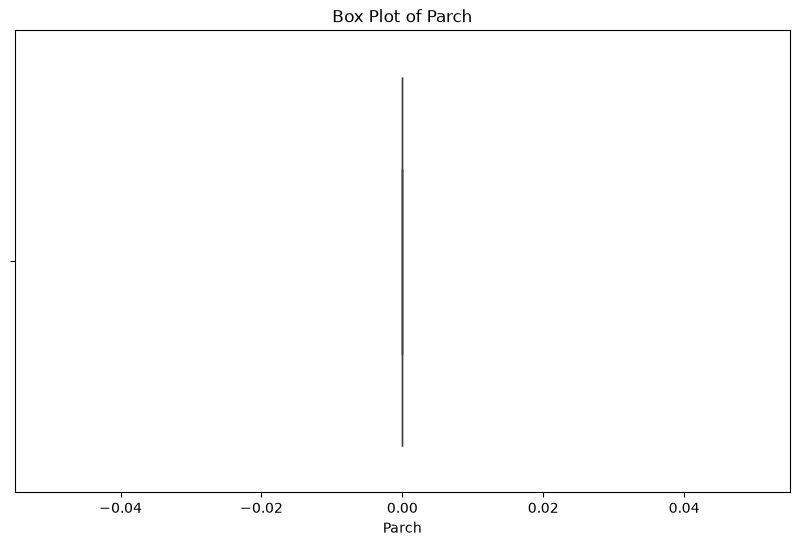

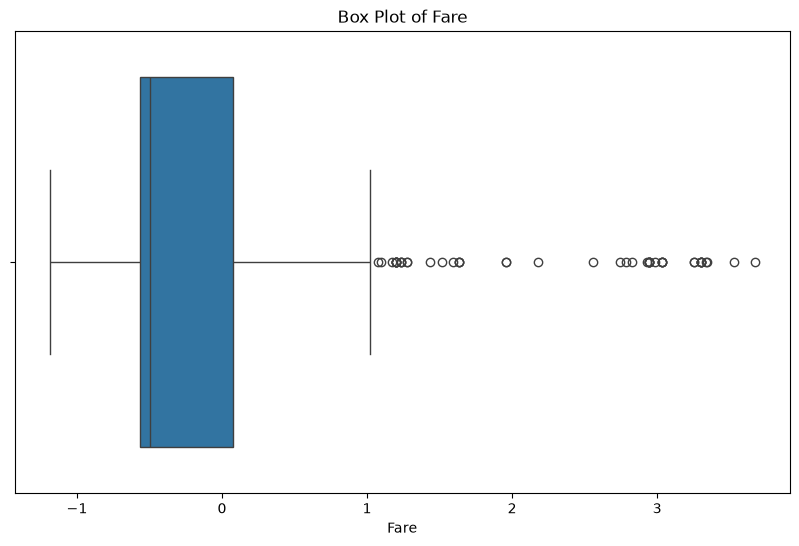

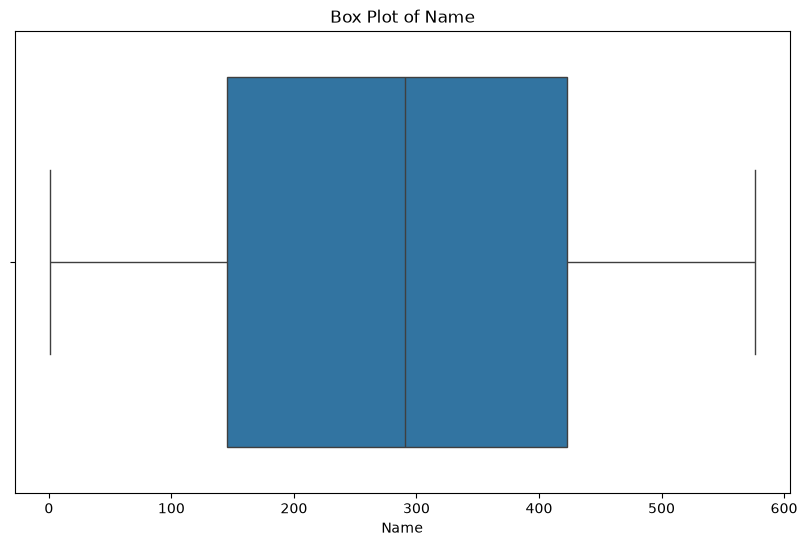

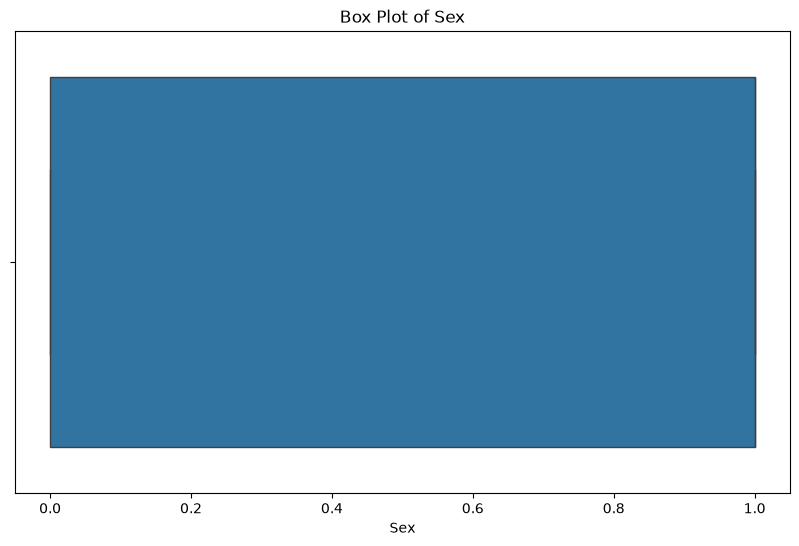

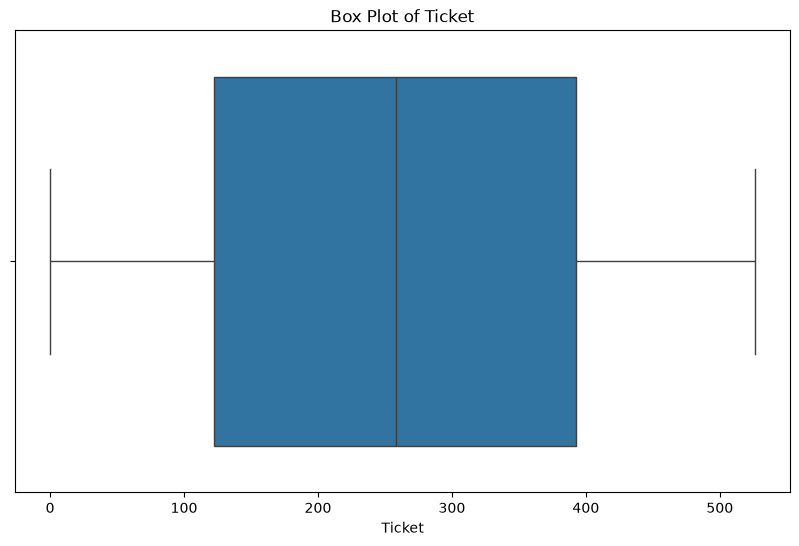

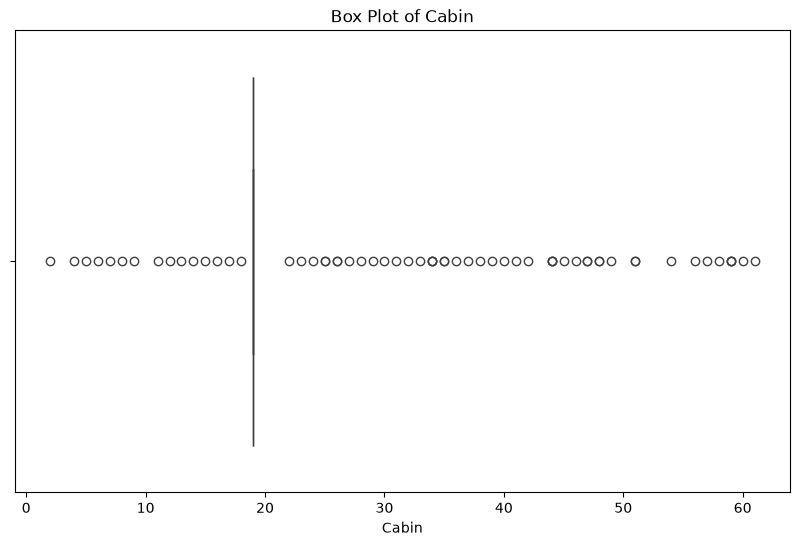

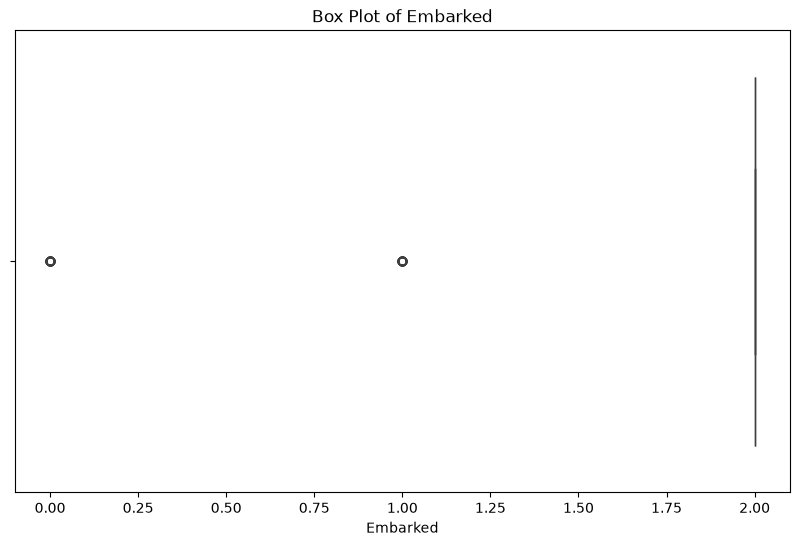

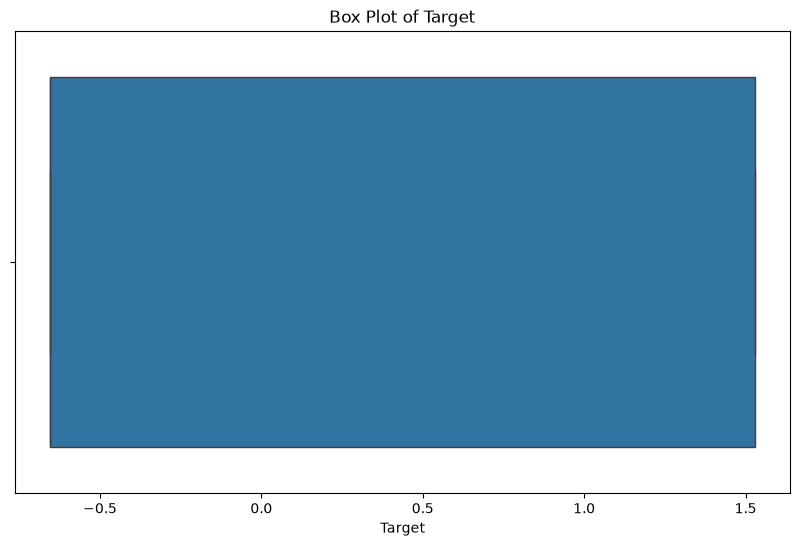

In [73]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

for feature in numeric_features:
    plt.figure(figsize=(10, 6))
    sns.boxplot(x=df[feature])
    plt.title(f'Box Plot of {feature}')
    plt.show()

In [74]:
Q1 = df[numeric_features].quantile(0.25)
Q3 = df[numeric_features].quantile(0.75)
IQR = Q3 - Q1

In [75]:
# Pastikan ulang kolom numerik terambil dari dataframe df yang aktif
numeric_features = df.select_dtypes(include=['number']).columns

# Hitung kembali Q1, Q3, dan IQR
Q1 = df[numeric_features].quantile(0.25)
Q3 = df[numeric_features].quantile(0.75)
IQR = Q3 - Q1

# Filter dataframe untuk menyaring outliers
condition = ~((df[numeric_features] < (Q1 - 1.5 * IQR)) | (df[numeric_features] > (Q3 + 1.5 * IQR)))
df_filtered_numeric = df.loc[condition.all(axis=1), numeric_features]

# Menggabungkan kembali dengan kolom kategorikal
categorical_features = df.select_dtypes(include=['object']).columns
df = pd.concat([df_filtered_numeric, df.loc[condition.all(axis=1), categorical_features]], axis=1)

Normalisasi dan Standardisasi Data

In [76]:
from sklearn.preprocessing import StandardScaler

# Standardisasi fitur numerik
scaler = StandardScaler()
df[numeric_features] = scaler.fit_transform(df[numeric_features])

Text(0.5, 1.0, 'Histogram Sebelum Standardisasi')

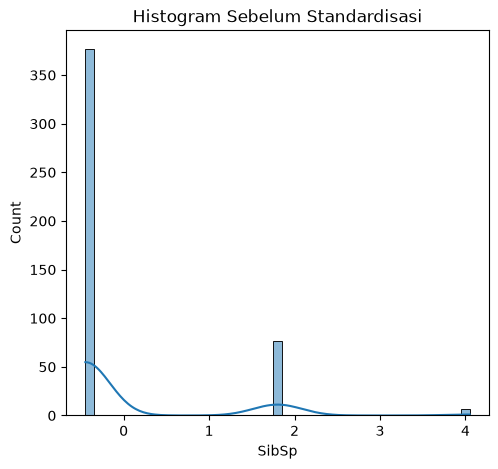

In [77]:
# Histogram Sebelum Standardisasi
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.histplot(train[numeric_features[3]], kde=True)
plt.title("Histogram Sebelum Standardisasi")

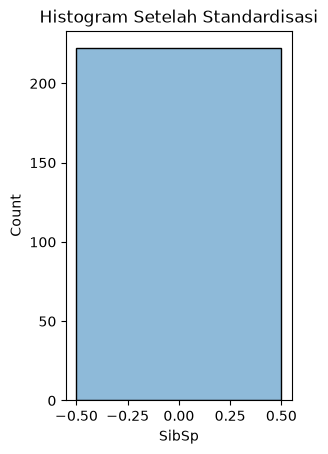

In [78]:
# Histogram Setelah Standardisasi
plt.subplot(1, 2, 2)
sns.histplot(df[numeric_features[3]], kde=True)
plt.title("Histogram Setelah Standardisasi")
plt.show()

Menangani Duplikasi Data

In [79]:
# Mengidentifikasi baris duplikat
duplicates = df.duplicated()
print("Baris duplikat:")
print(df[duplicates])

Baris duplikat:
Empty DataFrame
Columns: [PassengerId, Pclass, Age, SibSp, Parch, Fare, Name, Sex, Ticket, Cabin, Embarked, Target]
Index: []


In [80]:
# Menghapus baris duplikat
df = df.drop_duplicates()
print("DataFrame setelah menghapus duplikasi:")
print(df)

DataFrame setelah menghapus duplikasi:
     PassengerId    Pclass       Age  SibSp  Parch      Fare      Name  \
1       1.183414  0.589945  0.151252    0.0    0.0 -0.366711 -1.309981   
4       0.750561  0.589945 -1.225517    0.0    0.0 -0.343847 -1.142873   
6      -1.775724  0.589945  1.222072    0.0    0.0 -0.308591 -1.733719   
7      -1.378286  0.589945  0.151252    0.0    0.0 -0.343847  0.289482   
8      -0.835253  0.589945 -0.766594    0.0    0.0 -0.520081  0.104469   
..           ...       ...       ...    ...    ...       ...       ...   
449     0.423954  0.589945  0.151252    0.0    0.0 -0.308591  1.077277   
452    -0.677852  0.589945 -1.225517    0.0    0.0 -0.308591 -0.993669   
454     0.593160  0.589945  0.457200    0.0    0.0 -0.343847 -0.229747   
457    -0.921824 -1.394414 -0.001723    0.0    0.0  0.823166 -1.471120   
459    -0.327635  0.589945 -1.225517    0.0    0.0 -0.308591 -1.560643   

          Sex    Ticket  Cabin  Embarked    Target  
1    0.432627  0.11

Mengonversi Tipe Data

In [81]:
# Menampilkan kolom kategorikal pada dataset
category_features = df.select_dtypes(include=['object']).columns
df[category_features]

""
1
4
6
7
8
...
449
452
454
457


In [82]:
# Mengubah kolom kategorikal menjadi format biner (one-hot encoding)
df_one_hot = pd.get_dummies(df, columns=category_features)
df_one_hot

,PassengerId,Pclass,Age,SibSp,Parch,Fare,Name,Sex,Ticket,Cabin,Embarked,Target
1,1.183414,0.589945,0.151252,0.0,0.0,-0.366711,-1.309981,0.432627,0.117491,0.0,0.0,-0.468807
4,0.750561,0.589945,-1.225517,0.0,0.0,-0.343847,-1.142873,0.432627,-0.087386,0.0,0.0,-0.468807
6,-1.775724,0.589945,1.222072,0.0,0.0,-0.308591,-1.733719,0.432627,0.498987,0.0,0.0,-0.468807
7,-1.378286,0.589945,0.151252,0.0,0.0,-0.343847,0.289482,0.432627,-0.221616,0.0,0.0,-0.468807
8,-0.835253,0.589945,-0.766594,0.0,0.0,-0.520081,0.104469,0.432627,1.466856,0.0,0.0,-0.468807
...,...,...,...,...,...,...,...,...,...,...,...,...
449,0.423954,0.589945,0.151252,0.0,0.0,-0.308591,1.077277,0.432627,1.417403,0.0,0.0,-0.468807
452,-0.677852,0.589945,-1.225517,0.0,0.0,-0.308591,-0.993669,0.432627,0.873418,0.0,0.0,2.133073
454,0.593160,0.589945,0.457200,0.0,0.0,-0.343847,-0.229747,0.432627,-0.002609,0.0,0.0,-0.468807
457,-0.921824,-1.394414,-0.001723,0.0,0.0,0.823166,-1.471120,0.432627,-1.648693,0.0,0.0,-0.468807


In [83]:
from sklearn.preprocessing import LabelEncoder

# Inisialisasi LabelEncoder
label_encoder = LabelEncoder()
df_lencoder = pd.DataFrame(df)

for col in category_features:
    df_lencoder[col] = label_encoder.fit_transform(df[col])

# Menampilkan hasil label encoding
df_lencoder

,PassengerId,Pclass,Age,SibSp,Parch,Fare,Name,Sex,Ticket,Cabin,Embarked,Target
1,1.183414,0.589945,0.151252,0.0,0.0,-0.366711,-1.309981,0.432627,0.117491,0.0,0.0,-0.468807
4,0.750561,0.589945,-1.225517,0.0,0.0,-0.343847,-1.142873,0.432627,-0.087386,0.0,0.0,-0.468807
6,-1.775724,0.589945,1.222072,0.0,0.0,-0.308591,-1.733719,0.432627,0.498987,0.0,0.0,-0.468807
7,-1.378286,0.589945,0.151252,0.0,0.0,-0.343847,0.289482,0.432627,-0.221616,0.0,0.0,-0.468807
8,-0.835253,0.589945,-0.766594,0.0,0.0,-0.520081,0.104469,0.432627,1.466856,0.0,0.0,-0.468807
...,...,...,...,...,...,...,...,...,...,...,...,...
449,0.423954,0.589945,0.151252,0.0,0.0,-0.308591,1.077277,0.432627,1.417403,0.0,0.0,-0.468807
452,-0.677852,0.589945,-1.225517,0.0,0.0,-0.308591,-0.993669,0.432627,0.873418,0.0,0.0,2.133073
454,0.593160,0.589945,0.457200,0.0,0.0,-0.343847,-0.229747,0.432627,-0.002609,0.0,0.0,-0.468807
457,-0.921824,-1.394414,-0.001723,0.0,0.0,0.823166,-1.471120,0.432627,-1.648693,0.0,0.0,-0.468807


Latihan EDA & ExDA

In [84]:
df_lencoder.head()

,PassengerId,Pclass,Age,SibSp,Parch,Fare,Name,Sex,Ticket,Cabin,Embarked,Target
1,1.183414,0.589945,0.151252,0.0,0.0,-0.366711,-1.309981,0.432627,0.117491,0.0,0.0,-0.468807
4,0.750561,0.589945,-1.225517,0.0,0.0,-0.343847,-1.142873,0.432627,-0.087386,0.0,0.0,-0.468807
6,-1.775724,0.589945,1.222072,0.0,0.0,-0.308591,-1.733719,0.432627,0.498987,0.0,0.0,-0.468807
7,-1.378286,0.589945,0.151252,0.0,0.0,-0.343847,0.289482,0.432627,-0.221616,0.0,0.0,-0.468807
8,-0.835253,0.589945,-0.766594,0.0,0.0,-0.520081,0.104469,0.432627,1.466856,0.0,0.0,-0.468807


In [85]:
# Menghitung jumlah dan persentase missing values di setiap kolom
missing_values = df_lencoder.isnull().sum()
missing_percentage = (missing_values / len(df_lencoder)) * 100

missing_data = pd.DataFrame({
    'Missing Values': missing_values,
    'Percentage': missing_percentage
}).sort_values(by='Missing Values', ascending=False)

missing_data[missing_data['Missing Values'] > 0]  # Menampilkan kolom dengan missing values

,Missing Values,Percentage


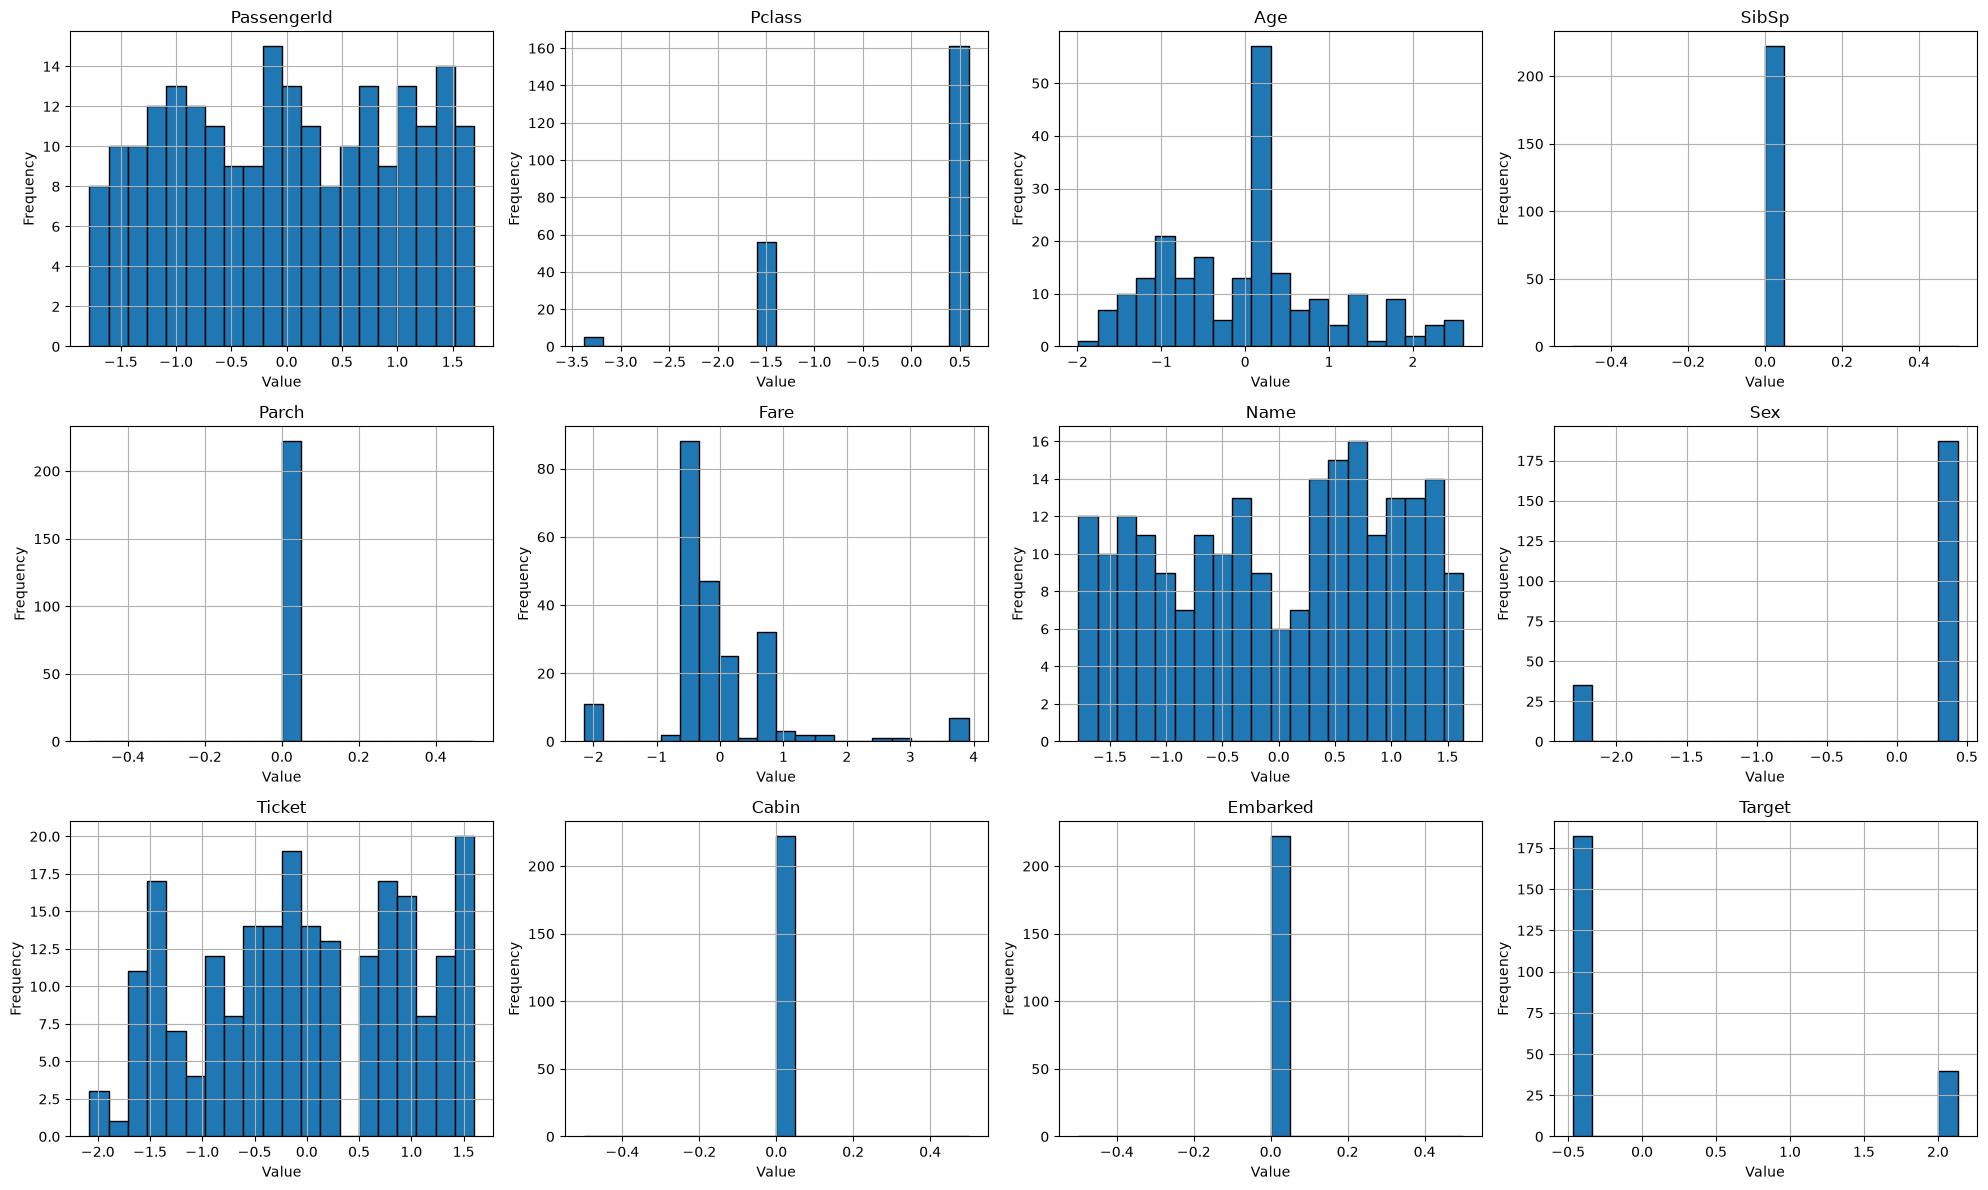

In [86]:
# Menghitung jumlah variabel
num_vars = df_lencoder.shape[1]

# Menentukan jumlah baris dan kolom untuk grid subplot
n_cols = 4  # Jumlah kolom yang diinginkan
n_rows = -(-num_vars // n_cols)  # Ceiling division untuk menentukan jumlah baris

# Membuat subplot
fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, n_rows * 4))

# Flatten axes array untuk memudahkan iterasi jika diperlukan
axes = axes.flatten()

# Plot setiap variabel
for i, column in enumerate(df_lencoder.columns):
    df_lencoder[column].hist(ax=axes[i], bins=20, edgecolor='black')
    axes[i].set_title(column)
    axes[i].set_xlabel('Value')
    axes[i].set_ylabel('Frequency')

# Menghapus subplot yang tidak terpakai (jika ada)
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

# Menyesuaikan layout agar lebih rapi
plt.tight_layout()
plt.show()

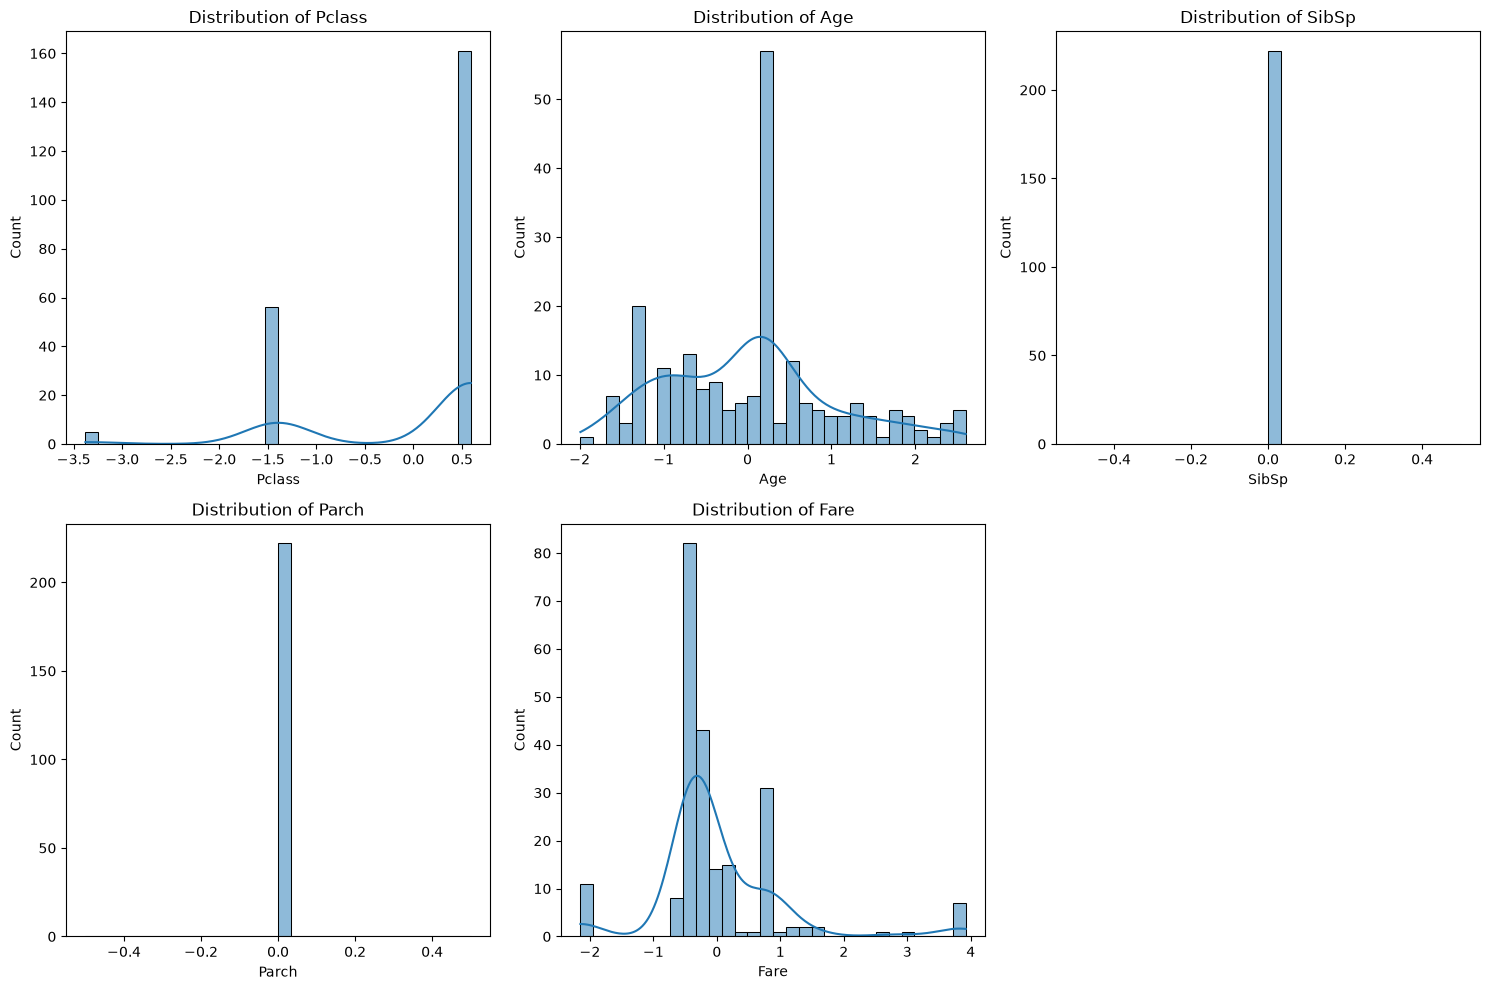

In [87]:
import matplotlib.pyplot as plt
import seaborn as sns

# Visualisasi distribusi data untuk beberapa kolom yang ada di dataset Titanic
columns_to_plot = ['Pclass', 'Age', 'SibSp', 'Parch', 'Fare']

plt.figure(figsize=(15, 10))
for i, column in enumerate(columns_to_plot, 1):
    plt.subplot(2, 3, i)
    sns.histplot(df_lencoder[column].dropna(), kde=True, bins=30)
    plt.title(f'Distribution of {column}')

plt.tight_layout()
plt.show()

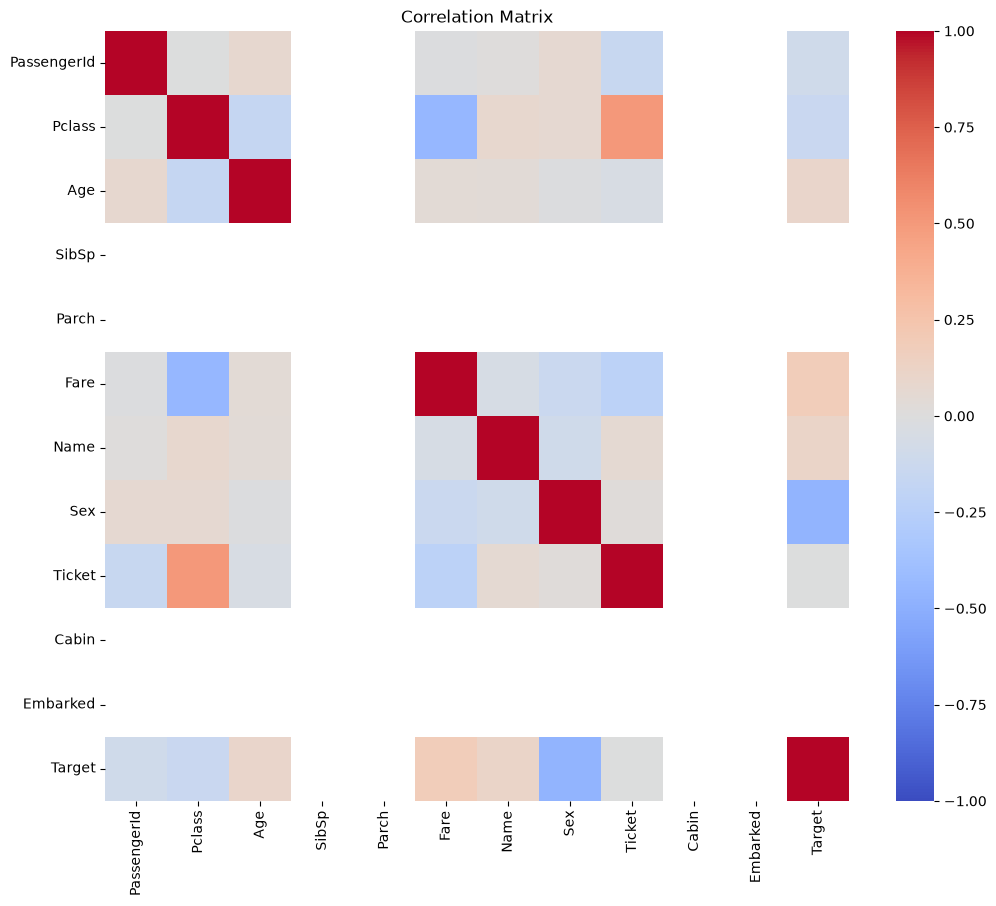

In [88]:
# Visualisasi korelasi antar variabel numerik
plt.figure(figsize=(12, 10))
correlation_matrix = df_lencoder.corr()

sns.heatmap(correlation_matrix, annot=False, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation Matrix')
plt.show()

In [89]:
from sklearn.datasets import fetch_california_housing
import pandas as pd

california = fetch_california_housing(as_frame=True)
df_lencoder = california.frame

Latihan: Data Splitting

In [90]:
import sklearn

In [91]:
# Memisahkan fitur (X) dan target (y)
X = df_lencoder.drop(columns=['MedHouseVal'])  
y = df_lencoder['MedHouseVal']

In [92]:
from sklearn.model_selection import train_test_split

# membagi dataset menjadi training dan testing 
x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1)

In [93]:
# menghitung panjang/jumlah data 
print("Jumlah data: ", len(X))

# menghitung panjang/jumlah data pada x_train
print("Jumlah data latih: ", len(x_train))

# menghitung panjang/jumlah data pada x_test
print("Jumlah data test: ", len(x_test))

Jumlah data:  20640
Jumlah data latih:  16512
Jumlah data test:  4128


Pembangunan Model (Modelling)

Melatih Model (Training)

In [98]:
# Melatih model 1 dengan algoritma Least Angle Regression
from sklearn import linear_model
lars = linear_model.Lars(n_nonzero_coefs=1).fit(x_train, y_train)

# Melatih model 2 dengan algoritma Linear Regression
from sklearn.linear_model import LinearRegression
LR = LinearRegression().fit(x_train, y_train)

# Melatih model 3 dengan algoritma Gradient Boosting Regressor
from sklearn.ensemble import GradientBoostingRegressor
GBR = GradientBoostingRegressor(random_state=184)
GBR.fit(x_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to each Tree estimator at eachboosting iteration.In addition, it controls the random permutation of the features ateach split (see Notes for more details).It also controls the random splitting of the training data to obtain avalidation set if `n_iter_no_change` is not None.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",184
,"loss loss: {'squared_error', 'absolute_error', 'huber', 'quantile'}, default='squared_error'Loss function to be optimized. 'squared_error' refers to the squarederror for regression. 'absolute_error' refers to the absolute error ofregression and is a robust loss function. 'huber' is acombination of the two. 'quantile' allows quantile regression (use`alpha` to specify the quantile).See:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_quantile.py`for an example that demonstrates quantile regression for creatingprediction intervals with `loss='quantile'`.",'squared_error'
,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.",0.1
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",100
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'This parameter has no effect... versionadded:: 0.18.. deprecated:: 1.9 `criterion` is deprecated and will be removed in 1.11.",'deprecated'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",3
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, in

Evaluasi Model

In [99]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Evaluasi pada model LARS
pred_lars = lars.predict(x_test)
mae_lars = mean_absolute_error(y_test, pred_lars)
mse_lars = mean_squared_error(y_test, pred_lars)
r2_lars = r2_score(y_test, pred_lars)

# Membuat dictionary untuk menyimpan hasil evaluasi
data = {
    'MAE': [mae_lars],
    'MSE': [mse_lars],
    'R2': [r2_lars]
}

# Konversi dictionary menjadi DataFrame
df_results = pd.DataFrame(data, index=['Lars'])
df_results

,MAE,MSE,R2
Lars,0.908828,1.312639,-0.000723


In [100]:
# Evaluasi pada model Linear Regression
pred_LR = LR.predict(x_test)
mae_LR = mean_absolute_error(y_test, pred_LR)
mse_LR = mean_squared_error(y_test, pred_LR)
r2_LR = r2_score(y_test, pred_LR)

# Menambahkan hasil evaluasi LR ke DataFrame
df_results.loc['Linear Regression'] = [mae_LR, mse_LR, r2_LR]
df_results

,MAE,MSE,R2
Lars,0.908828,1.312639,-0.000723
Linear Regression,0.532869,0.529140,0.596597


In [101]:
# Evaluasi pada model Gradient Boosting Regressor
pred_GBR = GBR.predict(x_test)
mae_GBR = mean_absolute_error(y_test, pred_GBR)
mse_GBR = mean_squared_error(y_test, pred_GBR)
r2_GBR = r2_score(y_test, pred_GBR)

# Menambahkan hasil evaluasi GBR ke DataFrame
df_results.loc['GradientBoostingRegressor'] = [mae_GBR, mse_GBR, r2_GBR]
df_results

,MAE,MSE,R2
Lars,0.908828,1.312639,-0.000723
Linear Regression,0.532869,0.529140,0.596597
GradientBoostingRegressor,0.369797,0.289845,0.779029


Menyimpan Model

Joblib

In [102]:
import joblib

# Menyimpan model ke dalam file
joblib.dump(GBR, 'gbr_model.joblib')

print("Model GBR berhasil disimpan ke file gbr_model.joblib!")

Model GBR berhasil disimpan ke file gbr_model.joblib!


Pickle

In [103]:
import pickle

# Menyimpan model ke dalam file
with open('gbr_model.pkl', 'wb') as file:
    pickle.dump(GBR, file)

print("Model GBR berhasil disimpan ke file gbr_model.pkl!")

Model GBR berhasil disimpan ke file gbr_model.pkl!


In [1]:
import pandas as pd

# Membaca file dataset (ganti nama filenya jika berbeda, misal train.csv atau test.csv)
df = pd.read_csv('train.csv')

# Menampilkan jumlah baris dan kolom
print(f"Jumlah baris: {df.shape[0]}")
print(f"Jumlah kolom: {df.shape[1]}")

# Kalau mau lihat ringkasan lengkapnya
print(df.info())

Jumlah baris: 16512
Jumlah kolom: 9
<class 'pandas.DataFrame'>
RangeIndex: 16512 entries, 0 to 16511
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   MedInc      16512 non-null  float64
 1   HouseAge    16512 non-null  float64
 2   AveRooms    16512 non-null  float64
 3   AveBedrms   16512 non-null  float64
 4   Population  16512 non-null  float64
 5   AveOccup    16512 non-null  float64
 6   Latitude    16512 non-null  float64
 7   Longitude   16512 non-null  float64
 8   Target      16512 non-null  float64
dtypes: float64(9)
memory usage: 1.1 MB
None
